In [46]:
import pandas as pd
from mplsoccer.pitch import Pitch
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

In [47]:
def get_event_locations(df, event=None, place=None, result=None, team=None):
    if event:
        df_event = df.loc[df['type_name'] == event]
    else:
        df_event = df
    if team:
        df_event = df_event.loc[df['team_id'] == team]
    if result:
        df_event = df_event.loc[df['result_name'] == result]
    location = [[x, y] for x,y in zip(df_event[f'{place}_x'].values, df_event[f'{place}_y'].values)]
    df_event['location'] = location
    location_xy = df_event.location.apply(pd.Series)
    location_xy.columns = ['x', 'y']
    return location_xy

def draw_heatmap(df, title, x_areas=12, y_areas=8, event=None, place=None, result=None, team=None):
    location_xy = get_event_locations(df, event=event, place=place, result=result, team=team)
    pitch = Pitch(line_zorder=2, line_color='black', pitch_type='uefa')
    fig, ax = pitch.grid(figheight=4, grid_height=0.9, title_height=0.06, axis=False,
                        endnote_height=0.04, title_space=0, endnote_space=0)
    bin_statistic = pitch.bin_statistic(location_xy.x, location_xy.y, statistic='count', bins=(x_areas, y_areas), normalize=False)
    bin_statistic["statistic"] = bin_statistic["statistic"]
    pcm  = pitch.heatmap(bin_statistic, cmap='Reds', edgecolor='grey', ax=ax['pitch'])
    ax_cbar = fig.add_axes((1, 0.093, 0.03, 0.786))
    cbar = plt.colorbar(pcm, cax=ax_cbar)
    fig.suptitle(title, fontsize = 16)
    plt.show()

In [49]:
def heatmap_drawing_flow(df):
    draw_heatmap(df, event='pass', place='start', result='success', title='Passes - success 12x8', x_areas=12, y_areas=8)
    draw_heatmap(df, event='pass', place='start', result='success', title='Passes - success 24x16', x_areas=24, y_areas=16)
    draw_heatmap(df, event='dribble', place='start', result='success', title='Dribble - success 12x8', x_areas=12, y_areas=8)
    draw_heatmap(df, event='dribble', place='start', result='success', title='Dribble - success 24x16', x_areas=24, y_areas=16)
    draw_heatmap(df, event='cross', place='start', result='success', title='Cross - success 12x8', x_areas=12, y_areas=8)
    draw_heatmap(df, event='cross', place='start', result='success', title='Cross - success 24x16', x_areas=24, y_areas=16)

In [50]:
figure(figsize=(8, 6), dpi=80)
# wsl2122['start_x'] = wsl2122['start_x'] * 1.142857142857143
# wsl2122['end_x'] = wsl2122['end_x'] * 1.142857142857143
# wsl2122['start_y'] = wsl2122['start_y'] * 1.176470588235294
# wsl2122['end_y'] = wsl2122['end_y'] * 1.176470588235294

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

## Example match

In [51]:
wsl2122 = pd.read_hdf('data-opta-woman-all/spadl-opta.h5', "games")
wsl2122

,game_id,season_id,competition_id,game_day,game_date,home_team_id,away_team_id,home_score,away_score
0,1077833,2019,550,1,2019-09-08 14:30:00,6272,636,2,1
1,1077836,2019,550,1,2019-09-08 12:30:00,6275,6924,1,0
2,1077837,2019,550,1,2019-09-08 14:00:00,6279,9669,0,1
3,1077835,2019,550,1,2019-09-07 15:00:00,6274,9165,0,0
4,1077834,2019,550,1,2019-09-08 14:00:00,6273,6277,0,1
...,...,...,...,...,...,...,...,...,...
127,2236321,2021,550,1,2021-09-03 19:45:00,14501,9669,2,0
128,2236447,2021,550,22,2022-05-08 12:00:00,6924,12162,1,0
129,2236320,2021,550,1,2021-09-04 13:30:00,6277,9660,0,4
130,2236446,2021,550,22,2022-05-08 12:00:00,9669,9660,0,4


In [52]:
example_match = pd.read_hdf('data-opta-woman-all/features.h5', "game_1077833")
example_match

,type_id_a0,type_id_a1,type_id_a2,type_pass_a0,type_cross_a0,type_throw_in_a0,type_freekick_crossed_a0,type_freekick_short_a0,type_corner_crossed_a0,type_corner_short_a0,...,time_seconds_a0,time_seconds_overall_a0,period_id_a1,time_seconds_a1,time_seconds_overall_a1,period_id_a2,time_seconds_a2,time_seconds_overall_a2,time_delta_1,time_delta_2
0,0,0,0,True,False,False,False,False,False,False,...,1.0,1.0,1,1.0,1.0,1,1.0,1.0,0.0,0.0
1,21,0,0,False,False,False,False,False,False,False,...,2.5,2.5,1,1.0,1.0,1,1.0,1.0,1.5,1.5
2,0,21,0,True,False,False,False,False,False,False,...,4.0,4.0,1,2.5,2.5,1,1.0,1.0,1.5,3.0
3,0,0,21,True,False,False,False,False,False,False,...,5.0,5.0,1,4.0,4.0,1,2.5,2.5,1.0,2.5
4,0,0,0,True,False,False,False,False,False,False,...,8.0,8.0,1,5.0,5.0,1,4.0,4.0,3.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1593,7,10,0,False,False,False,False,False,False,False,...,2934.0,5634.0,2,2932.0,5632.0,2,2932.0,5632.0,2.0,2.0
1594,21,7,10,False,False,False,False,False,False,False,...,2934.5,5634.5,2,2934.0,5634.0,2,2932.0,5632.0,0.5,2.5
1595,7,21,7,False,False,False,False,False,False,False,...,2935.0,5635.0,2,2934.5,5634.5,2,2934.0,5634.0,0.5,1.0
1596,21,7,21,False,False,False,False,False,False,False,...,2935.5,5635.5,2,2935.0,5635.0,2,2934.5,5634.5,0.5,1.0


In [53]:
example_match_pass = example_match[example_match['type_pass_a0'] == True]
example_match_pass.rename(columns = {'start_x_a0':'start_x', 'start_y_a0':'start_y', 'end_x_a0':'end_x', 'end_y_a0':'end_y'}, inplace = True)  # type: ignore

example_match_pass_success = example_match_pass[example_match_pass['result_success_a0'] == True]
example_match_pass_fail = example_match_pass[example_match_pass['result_success_a0'] == False]

C:\Users\mattyl\AppData\Local\Temp\ipykernel_24024\3026560175.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  example_match_pass.rename(columns = {'start_x_a0':'start_x', 'start_y_a0':'start_y', 'end_x_a0':'end_x', 'end_y_a0':'end_y'}, inplace = True)  # type: ignore


C:\Users\mattyl\AppData\Local\Temp\ipykernel_24024\239698371.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


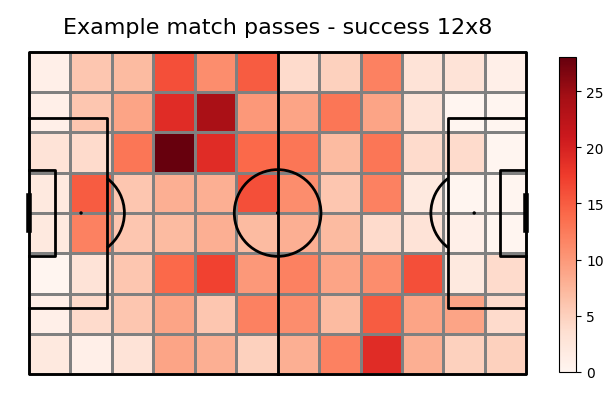

C:\Users\mattyl\AppData\Local\Temp\ipykernel_24024\239698371.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


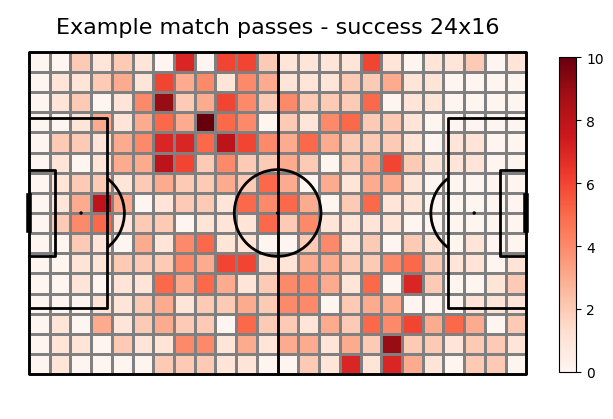

C:\Users\mattyl\AppData\Local\Temp\ipykernel_24024\239698371.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


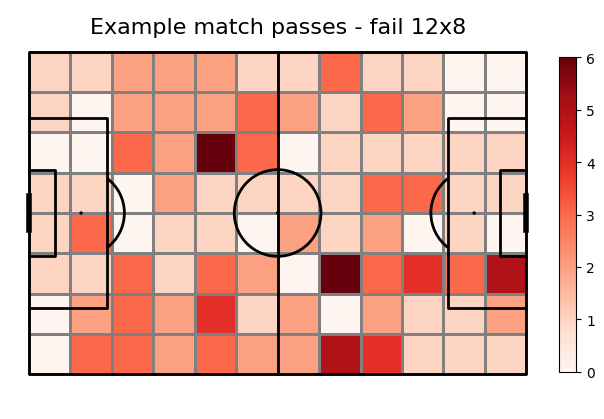

C:\Users\mattyl\AppData\Local\Temp\ipykernel_24024\239698371.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


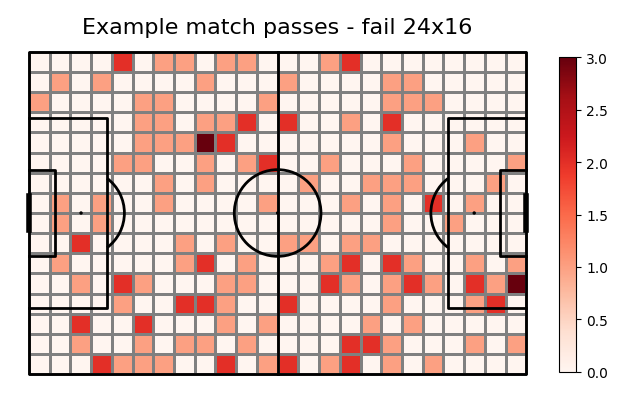

In [54]:
draw_heatmap(df=example_match_pass_success, place='start', title='Example match passes - success 12x8', x_areas=12, y_areas=8)
draw_heatmap(df=example_match_pass_success, place='start', title='Example match passes - success 24x16', x_areas=24, y_areas=16)
draw_heatmap(df=example_match_pass_fail, place='start', title='Example match passes - fail 12x8', x_areas=12, y_areas=8)
draw_heatmap(df=example_match_pass_fail, place='start', title='Example match passes - fail 24x16', x_areas=24, y_areas=16)

## opta women 2019-2020

In [55]:
wsl_2019_20 = pd.read_csv('wsl-2019-20.csv')
wsl_2019_20['type_name'].unique()

array(['pass', 'dribble', 'cross'], dtype=object)

In [56]:
wsl_all = pd.read_csv('wsl-all.csv')
wsl_all['type_name'].unique()

array(['pass', 'dribble', 'cross'], dtype=object)

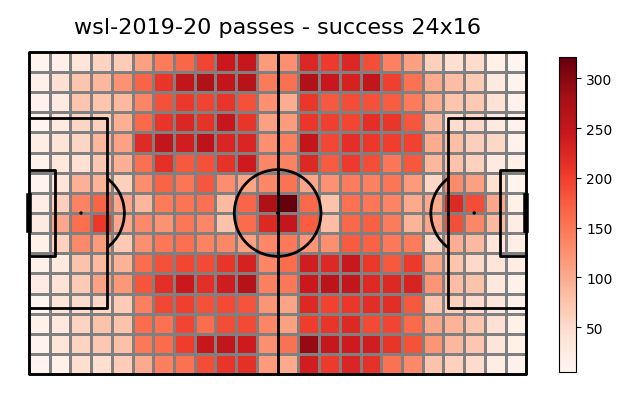

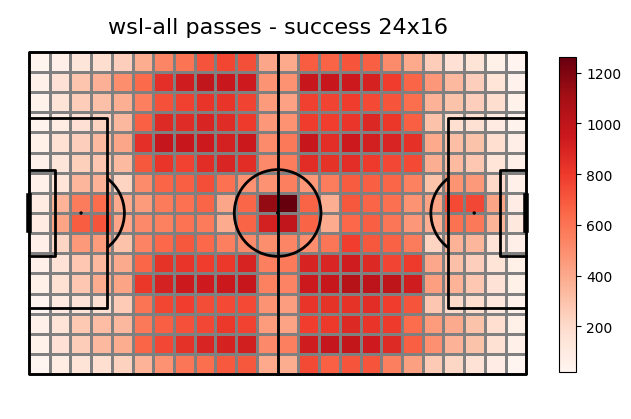

In [57]:
draw_heatmap(wsl_2019_20, event='pass', place='start', result='success', title='wsl-2019-20 passes - success 24x16', x_areas=24, y_areas=16)
draw_heatmap(wsl_all, event='pass', place='start', result='success', title='wsl-all passes - success 24x16', x_areas=24, y_areas=16)


## All three opta women seasons

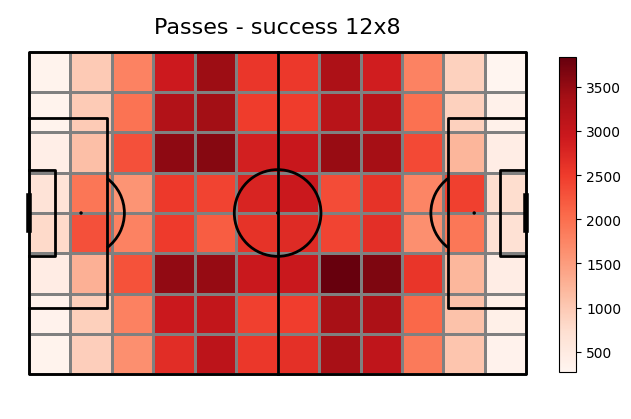

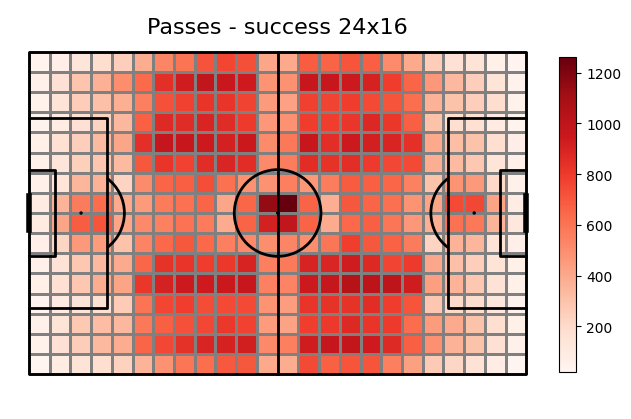

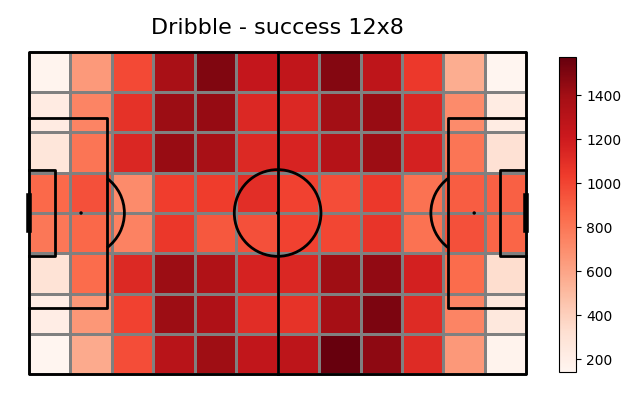

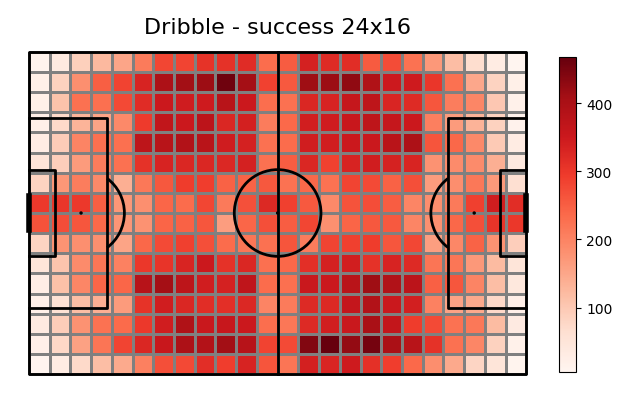

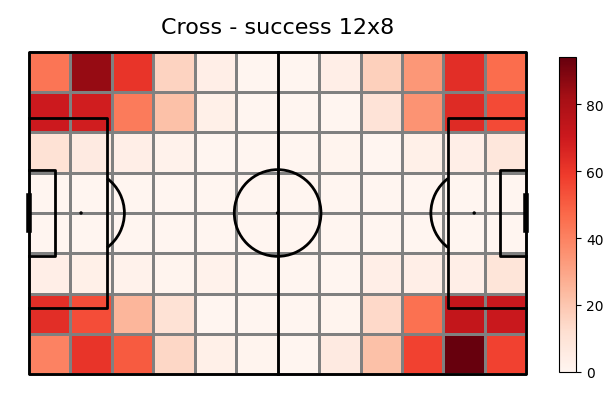

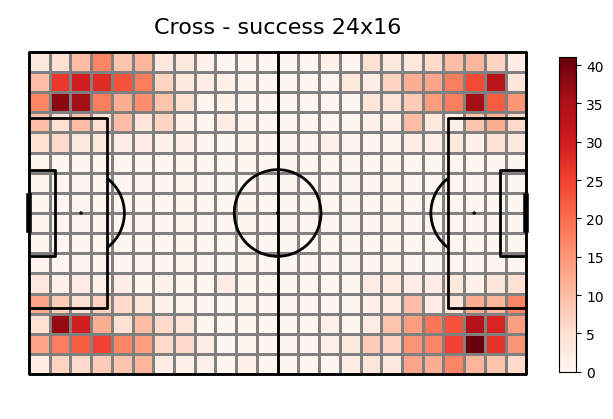

In [58]:
heatmap_drawing_flow(wsl_all)

In [59]:
from get_data.get_data import get_merged_events
from sequences.which_sector import *
from sequences.get_sequences import *
from sequences.get_sequences import get_sequence_location

In [60]:
from get_data.get_data import get_competitions
get_competitions()

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,38,235,Poland,Ekstraklasa,male,False,False,2022/2023,2023-02-28T19:59:50.171634,2023-02-28T23:02:40.230331,2023-02-27T19:31:38.361806,2023-02-28T19:59:50.171634
1,38,108,Poland,Ekstraklasa,male,False,False,2021/2022,2023-02-24T20:04:34.571034,2022-11-27T21:38:48.731552,2022-11-27T21:38:48.731552,2023-02-24T20:04:34.571034
2,38,90,Poland,Ekstraklasa,male,False,False,2020/2021,2022-11-24T20:55:43.582874,2022-08-16T20:44:23.378841,None,2022-11-24T20:55:43.582874
3,38,42,Poland,Ekstraklasa,male,False,False,2019/2020,2023-02-25T11:12:04.956514,2021-06-13T16:17:31.694,None,2023-02-25T11:12:04.956514
4,38,4,Poland,Ekstraklasa,male,False,False,2018/2019,2022-11-21T04:43:34.590780,2021-06-13T16:17:31.694,None,2022-11-21T04:43:34.590780
5,55,43,Europe,UEFA Euro,male,False,True,2020,2023-02-24T21:26:47.128979,2022-08-04T12:00,2022-08-04T12:00,2023-02-24T21:26:47.128979


In [13]:
from get_data.get_data import get_matches

matches = get_matches(38, 4)['match_id'].values[:20]
events = []
def_areas_x = 12
def_areas_y = 8
for match in matches:
    events_types_to_analize = ['passes']
    events.append(get_merged_events(events_types_to_analize, match))

# len(matches)
events = pd.concat(events, ignore_index=True)
events

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,location,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress
0,94e6383d-1dda-422a-9d9d-afeb31b0f123,5,1,00:00:00.825,0,0,Pass,2,Wisła Płock,From Kick Off,...,"[60.0, 40.0]",1.200700,[69201eea-7a44-4ec2-9a73-83681e3a248e],"{'recipient': {'id': 12829, 'name': 'Damian Ra...",11423,832,9889,,,
1,103aa589-7c56-4ab7-9d3e-9c5deb90be2a,8,1,00:00:02.934,0,2,Pass,2,Wisła Płock,From Kick Off,...,"[45.0, 47.0]",1.301125,[f3201dcd-115b-440b-bd54-b3a55a461459],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,12829,,,
2,ec87a378-29fb-4f01-b594-52f6feabced6,11,1,00:00:05.227,0,5,Pass,2,Wisła Płock,From Kick Off,...,"[34.0, 49.0]",1.864537,[382c66c4-f8f3-43ad-8f7c-54d364feeacd],"{'recipient': {'id': 8708, 'name': 'Adam Dźwig...",11423,832,8715,,,
3,70bac105-7454-4916-84a3-dce081ebb4a6,14,1,00:00:09.477,0,9,Pass,2,Wisła Płock,From Kick Off,...,"[34.0, 22.0]",1.691427,[f4a53d12-d38b-4c23-9113-63df182a06e1],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,8708,,,
4,15b7724b-291c-444e-8676-b8a7a306b5b5,17,1,00:00:12.491,0,12,Pass,2,Wisła Płock,From Kick Off,...,"[37.0, 49.0]",0.994743,[dc9f902d-d63a-4afa-b758-9b4bb66b7d0e],"{'recipient': {'id': 8718, 'name': 'Cezary Ste...",11423,832,8715,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17981,9d6c11e9-f597-4d58-b154-d287337c0db6,3048,2,00:49:58.700,94,58,Pass,201,Śląsk Wrocław,Regular Play,...,"[26.0, 19.0]",3.353000,[8962ca8b-e526-4f4c-8a42-d9443eef881c],"{'recipient': {'id': 8155, 'name': 'Marcin Rob...",14242,818,8154,,NaN,
17982,80118865-9065-4cf3-a6a3-8e3defe66d1b,3052,2,00:50:06.107,95,6,Pass,201,Śląsk Wrocław,Regular Play,...,"[69.0, 14.0]",1.146000,"[91160a29-5843-4ff1-ba07-86da1144d127, a6d9a86...","{'recipient': {'id': 12925, 'name': 'Jakub Łab...",14242,818,8155,True,NaN,
17983,ece39f0a-496d-49bf-9a78-bef4fb6d8072,3055,2,00:50:11.354,95,11,Pass,201,Śląsk Wrocław,Regular Play,...,"[77.0, 43.0]",3.217000,[932f5176-e225-4c87-979e-9330d21d3c0b],"{'recipient': {'id': 8143, 'name': 'Mateusz Ra...",14242,818,12925,,NaN,
17984,940c91d6-9c9c-4ea6-967c-da0f5c6a5174,3058,2,00:50:16.664,95,16,Pass,201,Śląsk Wrocław,Regular Play,...,"[117.0, 69.0]",1.032000,[fd26d76f-135c-4e9a-9e23-4a10dc2e7398],"{'recipient': {'id': 8141, 'name': 'Kamil Dank...",14242,818,8143,,NaN,


In [16]:

matches = get_matches(38, 4)['match_id'].values[21:40]
events2 = []
for match in matches:
    events_types_to_analize = ['passes']
    events2.append(get_merged_events(events_types_to_analize, match))

# len(matches)
events2 = pd.concat(events2, ignore_index=True)
events2

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,location,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress
0,a6197776-6f42-4647-b26f-6ac05868d8c6,5,1,00:00:01.259,0,1,Pass,2,Wisła Kraków,From Kick Off,...,"[61.0, 41.0]",1.172700,[9b17dec9-14f4-46f5-9da2-018c2f4cfaba],"{'recipient': {'id': 7870, 'name': 'Rafal Bogu...",22620,829,18779,,,NaN
1,dbdc013c-6db9-4ea9-918b-1600aacbea9f,8,1,00:00:03.164,0,3,Pass,2,Wisła Kraków,From Kick Off,...,"[47.5, 44.7]",0.740967,[2a18e9a9-1f87-4876-a01c-71f969660d64],"{'recipient': {'id': 24210, 'name': 'Vukan Sav...",22620,829,7870,,,NaN
2,74409b76-3c91-4760-bc93-351a41e958df,11,1,00:00:06.185,0,6,Pass,2,Wisła Kraków,From Kick Off,...,"[40.4, 31.5]",2.396166,[77061686-20d7-4a3c-92dd-3b08e00f3efa],"{'recipient': {'id': 26205, 'name': 'Daniel Ho...",22620,829,24210,,,NaN
3,bce40dc3-af8e-45c3-be3b-fc94759fa2ba,14,1,00:00:09.211,0,9,Pass,2,Wisła Kraków,From Kick Off,...,"[28.9, 54.1]",1.930340,[f43755e3-3961-4e55-a5c3-8d29b761cd5a],"{'recipient': {'id': 8979, 'name': 'Mateusz Li...",22620,829,26205,,,NaN
4,0e8f0665-2451-4a79-8124-a3bbbaf120f1,18,1,00:00:11.963,0,11,Pass,2,Wisła Kraków,From Kick Off,...,"[7.0, 44.5]",1.837268,"[0221199a-f663-42da-a2b4-6cb1aef91b38, b0dab48...","{'recipient': {'id': 26205, 'name': 'Daniel Ho...",22620,829,8979,True,,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17746,6d729fed-7a3d-4451-b6aa-52194854afde,3132,2,00:48:44.398,93,44,Pass,192,Lech Poznan,Regular Play,...,"[73.0, 65.0]",1.457550,"[8f928f52-7dd3-4ebd-a1fe-e06b3a9adf32, 9a3b62f...","{'recipient': {'id': 8728, 'name': 'Pedro Migu...",11454,747,12908,,,NaN
17747,90a3bb7c-5ebf-4e97-9a21-303ad2745453,3136,2,00:48:46.333,93,46,Pass,192,Lech Poznan,Regular Play,...,"[33.0, 25.0]",1.102200,[8281c1b2-917a-4f38-a773-c1351d6b2487],"{'recipient': {'id': 12097, 'name': 'Michal Si...",11454,747,13606,,,NaN
17748,fd9a7f5c-2694-4b94-b7c6-52601c05b089,3138,2,00:48:47.435,93,47,Pass,192,Lech Poznan,Regular Play,...,"[26.0, 21.0]",5.648400,"[59673df5-c9ea-4209-8367-efc886a83ae4, be92bf4...","{'recipient': {'id': 8974, 'name': 'Sebastian ...",11454,747,12097,,,NaN
17749,63c2342a-684f-40cb-9376-f934172e285d,3143,2,00:48:54.562,93,54,Pass,192,Lech Poznan,Regular Play,...,"[24.0, 73.0]",2.000300,[a2da0871-d9e1-4309-b3db-3863f0130003],"{'recipient': {'id': 4681, 'name': 'Jasmin Bur...",11454,747,4661,,,NaN


In [17]:
events = pd.concat([events, events2], ignore_index=True)

In [18]:
events

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,location,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress
0,94e6383d-1dda-422a-9d9d-afeb31b0f123,5,1,00:00:00.825,0,0,Pass,2,Wisła Płock,From Kick Off,...,"[60.0, 40.0]",1.200700,[69201eea-7a44-4ec2-9a73-83681e3a248e],"{'recipient': {'id': 12829, 'name': 'Damian Ra...",11423,832,9889,,,
1,103aa589-7c56-4ab7-9d3e-9c5deb90be2a,8,1,00:00:02.934,0,2,Pass,2,Wisła Płock,From Kick Off,...,"[45.0, 47.0]",1.301125,[f3201dcd-115b-440b-bd54-b3a55a461459],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,12829,,,
2,ec87a378-29fb-4f01-b594-52f6feabced6,11,1,00:00:05.227,0,5,Pass,2,Wisła Płock,From Kick Off,...,"[34.0, 49.0]",1.864537,[382c66c4-f8f3-43ad-8f7c-54d364feeacd],"{'recipient': {'id': 8708, 'name': 'Adam Dźwig...",11423,832,8715,,,
3,70bac105-7454-4916-84a3-dce081ebb4a6,14,1,00:00:09.477,0,9,Pass,2,Wisła Płock,From Kick Off,...,"[34.0, 22.0]",1.691427,[f4a53d12-d38b-4c23-9113-63df182a06e1],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,8708,,,
4,15b7724b-291c-444e-8676-b8a7a306b5b5,17,1,00:00:12.491,0,12,Pass,2,Wisła Płock,From Kick Off,...,"[37.0, 49.0]",0.994743,[dc9f902d-d63a-4afa-b758-9b4bb66b7d0e],"{'recipient': {'id': 8718, 'name': 'Cezary Ste...",11423,832,8715,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35732,6d729fed-7a3d-4451-b6aa-52194854afde,3132,2,00:48:44.398,93,44,Pass,192,Lech Poznan,Regular Play,...,"[73.0, 65.0]",1.457550,"[8f928f52-7dd3-4ebd-a1fe-e06b3a9adf32, 9a3b62f...","{'recipient': {'id': 8728, 'name': 'Pedro Migu...",11454,747,12908,,,NaN
35733,90a3bb7c-5ebf-4e97-9a21-303ad2745453,3136,2,00:48:46.333,93,46,Pass,192,Lech Poznan,Regular Play,...,"[33.0, 25.0]",1.102200,[8281c1b2-917a-4f38-a773-c1351d6b2487],"{'recipient': {'id': 12097, 'name': 'Michal Si...",11454,747,13606,,,NaN
35734,fd9a7f5c-2694-4b94-b7c6-52601c05b089,3138,2,00:48:47.435,93,47,Pass,192,Lech Poznan,Regular Play,...,"[26.0, 21.0]",5.648400,"[59673df5-c9ea-4209-8367-efc886a83ae4, be92bf4...","{'recipient': {'id': 8974, 'name': 'Sebastian ...",11454,747,12097,,,NaN
35735,63c2342a-684f-40cb-9376-f934172e285d,3143,2,00:48:54.562,93,54,Pass,192,Lech Poznan,Regular Play,...,"[24.0, 73.0]",2.000300,[a2da0871-d9e1-4309-b3db-3863f0130003],"{'recipient': {'id': 4681, 'name': 'Jasmin Bur...",11454,747,4661,,,NaN


In [19]:

matches = get_matches(38, 4)['match_id'].values[41:60]
events3 = []
for match in matches:
    events_types_to_analize = ['passes']
    events3.append(get_merged_events(events_types_to_analize, match))

# len(matches)
events3 = pd.concat(events3, ignore_index=True)
events3

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,out,counterpress
0,a2eb0058-cf76-43cd-815c-f3a7d13c936b,5,1,00:00:01.861,0,1,Pass,2,Arka Gdynia,From Kick Off,...,1.610600,[b1420bd4-b156-41ec-b706-d722675b2850],"{'recipient': {'id': 20910, 'name': 'Christian...",11518,821,7859,,,,
1,a60c01a7-b7b4-454d-af54-d0679c4bb20b,8,1,00:00:05.272,0,5,Pass,2,Arka Gdynia,From Kick Off,...,3.162700,"[9f51bbac-6e88-45f6-b8d6-5d81fc21d132, cc44495...","{'recipient': {'id': 9717, 'name': 'Maciej Jan...",11518,821,20910,,,,
2,db20e07a-98a3-49b0-8e90-ac320e27d34f,15,1,00:00:11.813,0,11,Pass,2,Arka Gdynia,From Kick Off,...,0.209500,"[0169118b-4619-4d17-955c-eeffbf9f57c2, 89f10a0...","{'recipient': {'id': 7868, 'name': 'Michal Jan...",11518,821,7879,,,,
3,abb1f6a7-f32d-4280-905e-119e72a86fa0,18,1,00:00:13.638,0,13,Pass,2,Arka Gdynia,From Kick Off,...,2.600000,[44cb3324-e33a-46d9-980a-f0884452f92d],"{'recipient': {'id': 7868, 'name': 'Michal Jan...",11518,821,9717,,,,
4,2824bdf7-fd59-4146-8c88-ce7d8af03f12,22,1,00:00:19.198,0,19,Pass,2,Arka Gdynia,From Kick Off,...,1.313393,"[6f14e18d-bca5-4436-b930-219d3f401db8, 83a88d4...","{'recipient': {'id': 7859, 'name': 'Aleksandyr...",11518,821,7868,True,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17218,3d119bbe-0473-4df2-baa1-b055713225a2,2914,2,00:46:18.636,91,18,Pass,187,Korona Kielce,From Kick Off,...,1.307000,"[98e2f50b-4f5c-446f-b049-92708f1d683c, cfe4257...","{'recipient': {'id': 8714, 'name': 'Damian Szy...",11460,833,9891,,,NaN,
17219,c3e6519b-f4c5-49d7-8732-2ca9ac4784ac,2918,2,00:47:03.642,92,3,Pass,188,Korona Kielce,From Free Kick,...,2.661300,"[8d3874f9-5447-418a-936b-8087ca6acf44, 97191f7...","{'recipient': {'id': 8022, 'name': 'Bartosz Ry...",11460,833,8019,,,NaN,
17220,2e9a0004-5037-423f-9aa3-2a35b72bf6df,2924,2,00:47:26.297,92,26,Pass,190,Wisła Płock,From Free Kick,...,3.480500,,"{'length': 66.007576, 'angle': 0.015150356, 'h...",11460,832,8722,,,NaN,
17221,570804b8-9e4e-48aa-8256-d2503a154351,2927,2,00:48:25.710,93,25,Pass,191,Wisła Płock,From Free Kick,...,1.208600,[6f181d70-cada-4f3d-b3f6-0ad4e689c5b5],"{'recipient': {'id': 8714, 'name': 'Damian Szy...",11460,832,8720,,,NaN,


In [20]:
events = pd.concat([events, events3], ignore_index=True)
events

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,94e6383d-1dda-422a-9d9d-afeb31b0f123,5,1,00:00:00.825,0,0,Pass,2,Wisła Płock,From Kick Off,...,1.200700,[69201eea-7a44-4ec2-9a73-83681e3a248e],"{'recipient': {'id': 12829, 'name': 'Damian Ra...",11423,832,9889,,,,NaN
1,103aa589-7c56-4ab7-9d3e-9c5deb90be2a,8,1,00:00:02.934,0,2,Pass,2,Wisła Płock,From Kick Off,...,1.301125,[f3201dcd-115b-440b-bd54-b3a55a461459],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,12829,,,,NaN
2,ec87a378-29fb-4f01-b594-52f6feabced6,11,1,00:00:05.227,0,5,Pass,2,Wisła Płock,From Kick Off,...,1.864537,[382c66c4-f8f3-43ad-8f7c-54d364feeacd],"{'recipient': {'id': 8708, 'name': 'Adam Dźwig...",11423,832,8715,,,,NaN
3,70bac105-7454-4916-84a3-dce081ebb4a6,14,1,00:00:09.477,0,9,Pass,2,Wisła Płock,From Kick Off,...,1.691427,[f4a53d12-d38b-4c23-9113-63df182a06e1],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,8708,,,,NaN
4,15b7724b-291c-444e-8676-b8a7a306b5b5,17,1,00:00:12.491,0,12,Pass,2,Wisła Płock,From Kick Off,...,0.994743,[dc9f902d-d63a-4afa-b758-9b4bb66b7d0e],"{'recipient': {'id': 8718, 'name': 'Cezary Ste...",11423,832,8715,,,,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52955,3d119bbe-0473-4df2-baa1-b055713225a2,2914,2,00:46:18.636,91,18,Pass,187,Korona Kielce,From Kick Off,...,1.307000,"[98e2f50b-4f5c-446f-b049-92708f1d683c, cfe4257...","{'recipient': {'id': 8714, 'name': 'Damian Szy...",11460,833,9891,,,,NaN
52956,c3e6519b-f4c5-49d7-8732-2ca9ac4784ac,2918,2,00:47:03.642,92,3,Pass,188,Korona Kielce,From Free Kick,...,2.661300,"[8d3874f9-5447-418a-936b-8087ca6acf44, 97191f7...","{'recipient': {'id': 8022, 'name': 'Bartosz Ry...",11460,833,8019,,,,NaN
52957,2e9a0004-5037-423f-9aa3-2a35b72bf6df,2924,2,00:47:26.297,92,26,Pass,190,Wisła Płock,From Free Kick,...,3.480500,,"{'length': 66.007576, 'angle': 0.015150356, 'h...",11460,832,8722,,,,NaN
52958,570804b8-9e4e-48aa-8256-d2503a154351,2927,2,00:48:25.710,93,25,Pass,191,Wisła Płock,From Free Kick,...,1.208600,[6f181d70-cada-4f3d-b3f6-0ad4e689c5b5],"{'recipient': {'id': 8714, 'name': 'Damian Szy...",11460,832,8720,,,,NaN


In [38]:
events['event'][16]

{'recipient': {'id': 8428, 'name': 'Piotr Parzyszek'},
 'length': 58.00862,
 'angle': -0.017239671,
 'height': {'id': 3, 'name': 'High Pass'},
 'end_location': [107.0, 25.0],
 'body_part': {'id': 40, 'name': 'Right Foot'},
 'outcome': {'id': 9, 'name': 'Incomplete'}}

In [43]:
stats_bomb_pass_complete = events

for id, event_col in zip(events['id'].values, events['event'].values):
    if 'Incomplete' in str(event_col):
        stats_bomb_pass_complete = stats_bomb_pass_complete[stats_bomb_pass_complete['id'] != id]

stats_bomb_pass_complete

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,94e6383d-1dda-422a-9d9d-afeb31b0f123,5,1,00:00:00.825,0,0,Pass,2,Wisła Płock,From Kick Off,...,1.200700,[69201eea-7a44-4ec2-9a73-83681e3a248e],"{'recipient': {'id': 12829, 'name': 'Damian Ra...",11423,832,9889,,,,NaN
1,103aa589-7c56-4ab7-9d3e-9c5deb90be2a,8,1,00:00:02.934,0,2,Pass,2,Wisła Płock,From Kick Off,...,1.301125,[f3201dcd-115b-440b-bd54-b3a55a461459],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,12829,,,,NaN
2,ec87a378-29fb-4f01-b594-52f6feabced6,11,1,00:00:05.227,0,5,Pass,2,Wisła Płock,From Kick Off,...,1.864537,[382c66c4-f8f3-43ad-8f7c-54d364feeacd],"{'recipient': {'id': 8708, 'name': 'Adam Dźwig...",11423,832,8715,,,,NaN
3,70bac105-7454-4916-84a3-dce081ebb4a6,14,1,00:00:09.477,0,9,Pass,2,Wisła Płock,From Kick Off,...,1.691427,[f4a53d12-d38b-4c23-9113-63df182a06e1],"{'recipient': {'id': 8715, 'name': 'Alan Uryga...",11423,832,8708,,,,NaN
4,15b7724b-291c-444e-8676-b8a7a306b5b5,17,1,00:00:12.491,0,12,Pass,2,Wisła Płock,From Kick Off,...,0.994743,[dc9f902d-d63a-4afa-b758-9b4bb66b7d0e],"{'recipient': {'id': 8718, 'name': 'Cezary Ste...",11423,832,8715,,,,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52953,3b65402c-686f-4fd6-8f14-aaab3968595a,2910,2,00:46:14.774,91,14,Pass,187,Korona Kielce,From Kick Off,...,1.009696,[bd2883ba-2b6b-4902-9f9d-8383d2904658],"{'recipient': {'id': 8027, 'name': 'Mateusz Mo...",11460,833,8037,,True,,NaN
52955,3d119bbe-0473-4df2-baa1-b055713225a2,2914,2,00:46:18.636,91,18,Pass,187,Korona Kielce,From Kick Off,...,1.307000,"[98e2f50b-4f5c-446f-b049-92708f1d683c, cfe4257...","{'recipient': {'id': 8714, 'name': 'Damian Szy...",11460,833,9891,,,,NaN
52957,2e9a0004-5037-423f-9aa3-2a35b72bf6df,2924,2,00:47:26.297,92,26,Pass,190,Wisła Płock,From Free Kick,...,3.480500,,"{'length': 66.007576, 'angle': 0.015150356, 'h...",11460,832,8722,,,,NaN
52958,570804b8-9e4e-48aa-8256-d2503a154351,2927,2,00:48:25.710,93,25,Pass,191,Wisła Płock,From Free Kick,...,1.208600,[6f181d70-cada-4f3d-b3f6-0ad4e689c5b5],"{'recipient': {'id': 8714, 'name': 'Damian Szy...",11460,832,8720,,,,NaN


In [44]:
from dataframe_modify.add_positions import add_positions

stats_bomb_pass_complete = add_positions(stats_bomb_pass_complete)

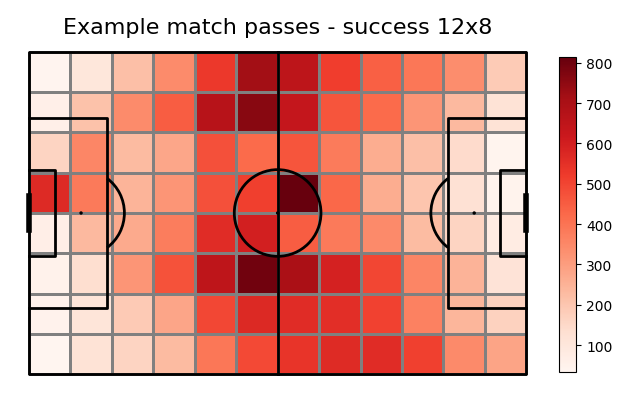

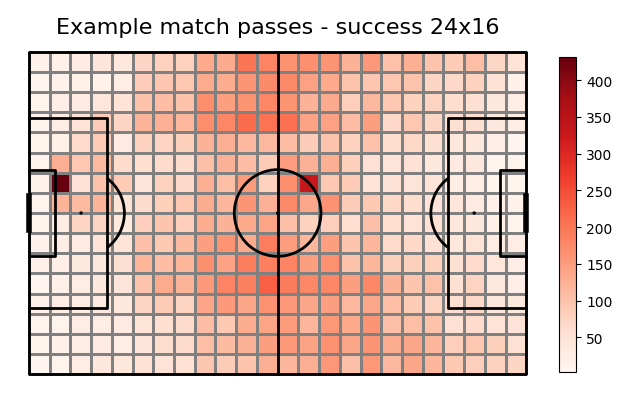

In [48]:
draw_heatmap(df=stats_bomb_pass_complete, place='start', title='Example match passes - success 12x8', x_areas=12, y_areas=8)
draw_heatmap(df=stats_bomb_pass_complete, place='start', title='Example match passes - success 24x16', x_areas=24, y_areas=16)